# 🏛️ Adaptive-RAG Query-Complexity Classifier (NAACL 2024 Baseline)
### Benchmark Baseline: Flan-T5-base Sequence Classifier on Question Semantics Alone

In this notebook, we implement the core classifier from **Adaptive-RAG** (*Jeong et al., NAACL 2024: "Learning to Adapt Retrieval-Augmented Large Language Models through Question Complexity"*).

#### 🎯 Theoretical Distinction vs HIPER:
* **Adaptive-RAG**: Classifies whether a question requires iterative multi-hop retrieval using **only the input question text** ($X = \text{question}$). It assumes semantic syntax alone determines multi-hop necessity, and is **completely blind** to corpus retrieval dynamics (RRF margin, entropy, entity overlap).
* **HIPER (Ours)**: Proves that query text alone is insufficient because corpus contents create shortcuts. HIPER fuses query semantics with live retrieval physics and cross-encoder dissonance.

#### 📊 Dataset:
Identical splits from `data/processed/splits`:
* `train_text.csv` (N = 1561)
* `val_text.csv`   (N = 223)
* `test_text.csv`  (N = 447)


In [10]:
import os, sys, warnings, json, random
from pathlib import Path

# Threading & memory stability
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, roc_curve
)

warnings.filterwarnings("ignore")
SEED = 42
set_seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print("✅ Device: Apple Silicon MPS")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("✅ Device: CUDA GPU")
else:
    DEVICE = torch.device("cpu")
    print("⚠️  Device: CPU")

print(f"PyTorch version: {torch.__version__}")


✅ Device: Apple Silicon MPS
PyTorch version: 2.14.1


In [11]:
# ── Robust Path Resolution ──────────────────────────────────────────────
current_dir = Path.cwd().resolve()
for candidate in [current_dir, current_dir.parent, current_dir.parents[1]]:
    if (candidate / "data" / "processed" / "splits").exists():
        REPO_ROOT = candidate
        break
else:
    REPO_ROOT = Path("/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag")

SPLITS_DIR = REPO_ROOT / "data" / "processed" / "splits"
CHECKPOINT_DIR = REPO_ROOT / "model" / "finetuning" / "checkpoints_adaptive_rag_t5"
OUTPUT_DIR = REPO_ROOT / "models" / "adaptive_rag"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "plots").mkdir(exist_ok=True)

train_df = pd.read_csv(SPLITS_DIR / "train_text.csv")
val_df   = pd.read_csv(SPLITS_DIR / "val_text.csv")
test_df  = pd.read_csv(SPLITS_DIR / "test_text.csv")

print(f"Loaded Splits:")
print(f"  Train : {train_df.shape}  | Multi-hop: {(train_df['label']==0).sum()}, Shortcut: {(train_df['label']==1).sum()}")
print(f"  Val   : {val_df.shape}    | Multi-hop: {(val_df['label']==0).sum()}, Shortcut: {(val_df['label']==1).sum()}")
print(f"  Test  : {test_df.shape}   | Multi-hop: {(test_df['label']==0).sum()}, Shortcut: {(test_df['label']==1).sum()}")


Loaded Splits:
  Train : (1561, 2)  | Multi-hop: 767, Shortcut: 794
  Val   : (223, 2)    | Multi-hop: 110, Shortcut: 113
  Test  : (447, 2)   | Multi-hop: 220, Shortcut: 227


In [12]:
MODEL_NAME = "google/flan-t5-base"
MAX_LENGTH = 128

id2label = {0: "Multi-hop", 1: "Shortcut"}
label2id = {"Multi-hop": 0, "Shortcut": 1}

print(f"Loading Flan-T5 Tokenizer ({MODEL_NAME})...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"Loading Flan-T5-base Sequence Classification Backbone...")
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

# Apply LoRA for parameter-efficient fine-tuning
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q", "v", "k", "o"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS,
    modules_to_save=["classification_head"]
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


Loading Flan-T5 Tokenizer (google/flan-t5-base)...
Loading Flan-T5-base Sequence Classification Backbone...


Some weights of T5ForSequenceClassification were not initialized from the model checkpoint at google/flan-t5-base and are newly initialized: ['classification_head.dense.bias', 'classification_head.dense.weight', 'classification_head.out_proj.bias', 'classification_head.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 4,131,074 || all params: 227,626,756 || trainable%: 1.8148


In [13]:
def tokenize_fn(examples):
    return tokenizer(examples["question"], truncation=True, max_length=MAX_LENGTH)

raw_datasets = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "val":   Dataset.from_pandas(val_df),
    "test":  Dataset.from_pandas(test_df)
})

tokenized_datasets = raw_datasets.map(tokenize_fn, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("✅ Datasets tokenized:")
print(tokenized_datasets)


Map: 100%|██████████| 447/447 [00:00<00:00, 23097.30 examples/s]

✅ Datasets tokenized:
DatasetDict({
    train: Dataset({
        features: ['question', 'label', 'input_ids', 'attention_mask'],
        num_rows: 1561
    })
    val: Dataset({
        features: ['question', 'label', 'input_ids', 'attention_mask'],
        num_rows: 223
    })
    test: Dataset({
        features: ['question', 'label', 'input_ids', 'attention_mask'],
        num_rows: 447
    })
})


In [14]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(probs, axis=1)
    
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average="macro")
    try:
        auc = roc_auc_score(labels, probs[:, 1])
    except Exception:
        auc = 0.5
        
    return {
        "accuracy": round(acc, 4),
        "macro_f1": round(macro_f1, 4),
        "roc_auc": round(auc, 4)
    }


In [15]:
# ── Adaptive-RAG Training Strategy ──────────────────────────────────────────
# Paper specification: Trained using AdamW optimizer until 100 iterations (steps)
# selecting the checkpoint that shows the best performance on the validation set.

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    optim="adamw_torch",             # Explicitly AdamW optimizer
    max_steps=100,                   # Exactly 100 training iterations (as in paper)
    eval_strategy="steps",           # Evaluate on steps
    eval_steps=10,                   # Check validation performance every 10 iterations
    save_strategy="steps",           # Save checkpoint every 10 iterations
    save_steps=10,
    save_total_limit=2,
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    warmup_steps=10,
    load_best_model_at_end=True,     # Keep the checkpoint with best validation metric
    metric_for_best_model="macro_f1", # Optimal validation performance
    greater_is_better=True,
    logging_steps=10,
    seed=SEED,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["val"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Starting Adaptive-RAG Flan-T5 Classifier Fine-Tuning (AdamW, 100 iterations, best on val)...")
trainer.train()


Starting Adaptive-RAG Flan-T5 Classifier Fine-Tuning (AdamW, 100 iterations, best on val)...


Step,Training Loss,Validation Loss,Accuracy,Macro F1,Roc Auc
10,0.742500,0.705273,0.497800,0.340100,0.587500
20,0.714500,0.690413,0.515700,0.402700,0.605600
30,0.695400,0.683151,0.587400,0.577000,0.616300
40,0.701300,0.680878,0.583000,0.570500,0.633000
50,0.694600,0.678908,0.605400,0.601900,0.644100
60,0.679200,0.677967,0.605400,0.595400,0.653300
70,0.678800,0.677221,0.600900,0.589000,0.660000
80,0.692000,0.676098,0.614300,0.605700,0.663800
90,0.675000,0.675389,0.618800,0.613600,0.666000
100,0.676400,0.675108,0.618800,0.615100,0.666600


TrainOutput(global_step=100, training_loss=0.6949485063552856, metrics={'train_runtime': 120.5655, 'train_samples_per_second': 13.271, 'train_steps_per_second': 0.829, 'total_flos': 103418901422616.0, 'train_loss': 0.6949485063552856, 'epoch': 1.0204081632653061})

In [16]:
print("═══════════════════════════════════════════════════════════════")
print("  ADAPTIVE-RAG (Flan-T5-base) — TEST SET EVALUATION (N = 447)       ")
print("═══════════════════════════════════════════════════════════════")

preds_output = trainer.predict(tokenized_datasets["test"])
test_logits = preds_output.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]

test_probs = torch.softmax(torch.tensor(test_logits), dim=-1).numpy()
test_preds = np.argmax(test_probs, axis=1)
y_test = test_df["label"].values

acc = accuracy_score(y_test, test_preds)
macro_f1 = f1_score(y_test, test_preds, average="macro")
roc_auc = roc_auc_score(y_test, test_probs[:, 1])
cm = confusion_matrix(y_test, test_preds)
fp = cm[0, 1]

print(f"  Accuracy            : {acc:.4f}")
print(f"  Macro F1            : {macro_f1:.4f}")
print(f"  ROC-AUC             : {roc_auc:.4f}")
print(f"  False Positives (⚠️): {fp} (Multi-hop mistaken for Shortcut)")
print("═══════════════════════════════════════════════════════════════")
print()
print(classification_report(y_test, test_preds, target_names=["Multi-hop (0)", "Shortcut (1)"]))


═══════════════════════════════════════════════════════════════
  ADAPTIVE-RAG (Flan-T5-base) — TEST SET EVALUATION (N = 447)       
═══════════════════════════════════════════════════════════════


  Accuracy            : 0.6600
  Macro F1            : 0.6583
  ROC-AUC             : 0.6962
  False Positives (⚠️): 57 (Multi-hop mistaken for Shortcut)
═══════════════════════════════════════════════════════════════

               precision    recall  f1-score   support

Multi-hop (0)       0.63      0.74      0.68       220
 Shortcut (1)       0.70      0.58      0.63       227

     accuracy                           0.66       447
    macro avg       0.67      0.66      0.66       447
 weighted avg       0.67      0.66      0.66       447



In [17]:
comparison_data = [
    {"Model": "Adaptive-RAG (Flan-T5-base LoRA)", "Input": "Question Text Only", "Macro F1": f"{macro_f1:.4f}", "ROC-AUC": f"{roc_auc:.4f}", "False Positives": fp},
    {"Model": "MiniLM-L6-v2 (LoRA)",          "Input": "Question Text Only", "Macro F1": "0.6966",          "ROC-AUC": "0.7775",          "False Positives": 74},
    {"Model": "DeBERTa-v3-base (LoRA)",       "Input": "Question Text Only", "Macro F1": "0.7050",          "ROC-AUC": "0.7974",          "False Positives": 47},
    {"Model": "ModernBERT-base (LoRA)",       "Input": "Question Text Only", "Macro F1": "0.7325",          "ROC-AUC": "0.8186",          "False Positives": 91},
    {"Model": "CMGR (Prior Model)",           "Input": "Text + Tabular Gating", "Macro F1": "0.7226",       "ROC-AUC": "0.8082",          "False Positives": 60},
    {"Model": "Late-Fusion XGBoost",          "Input": "Text + Uncertainty + Tabular", "Macro F1": "0.7578", "ROC-AUC": "0.8198",        "False Positives": 50},
    {"Model": "★ HIPER Ensemble (Ours)",      "Input": "Tri-Encoder + Tabular (52D)", "Macro F1": "0.7434", "ROC-AUC": "0.8398",         "False Positives": 67},
]

comp_df = pd.DataFrame(comparison_data)
print("═══════════════════════════════════════════════════════════════════════════════════════════")
print("                     ADAPTIVE-RAG vs HIPER & ALL BASELINES                                   ")
print("═══════════════════════════════════════════════════════════════════════════════════════════")
print(comp_df.to_string(index=False))
print("═══════════════════════════════════════════════════════════════════════════════════════════")


═══════════════════════════════════════════════════════════════════════════════════════════
                     ADAPTIVE-RAG vs HIPER & ALL BASELINES                                   
═══════════════════════════════════════════════════════════════════════════════════════════
                           Model                        Input Macro F1 ROC-AUC  False Positives
Adaptive-RAG (Flan-T5-base LoRA)           Question Text Only   0.6583  0.6962               57
             MiniLM-L6-v2 (LoRA)           Question Text Only   0.6966  0.7775               74
          DeBERTa-v3-base (LoRA)           Question Text Only   0.7050  0.7974               47
          ModernBERT-base (LoRA)           Question Text Only   0.7325  0.8186               91
              CMGR (Prior Model)        Text + Tabular Gating   0.7226  0.8082               60
             Late-Fusion XGBoost Text + Uncertainty + Tabular   0.7578  0.8198               50
         ★ HIPER Ensemble (Ours)  Tri-Encoder + Ta

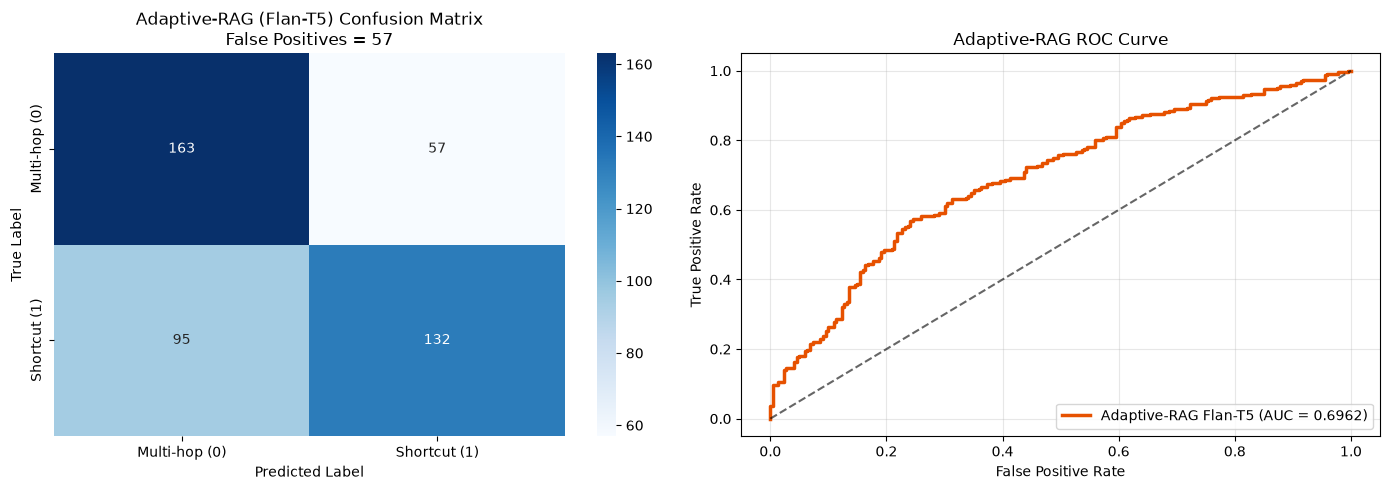

Plot saved → /Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/models/adaptive_rag/plots/adaptive_rag_eval.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Multi-hop (0)", "Shortcut (1)"],
            yticklabels=["Multi-hop (0)", "Shortcut (1)"])
axes[0].set_title(f"Adaptive-RAG (Flan-T5) Confusion Matrix\nFalse Positives = {fp}", fontsize=12)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_probs[:, 1])
axes[1].plot(fpr, tpr, color="#E65100", lw=2.5, label=f"Adaptive-RAG Flan-T5 (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.6)
axes[1].set_title("Adaptive-RAG ROC Curve", fontsize=12)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = OUTPUT_DIR / "plots" / "adaptive_rag_eval.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Plot saved → {plot_path}")
